In [6]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

Original time: 120 dt. Running on 4 qubits:
```

```

**2x (240 dt) time experiments**

- Rough calibration: ('cvyrrjjkpn400082m5pg', 'cvyrrk26xzjg0084hz40')
- Rough Gaussian calibration: ('cvyrrktqfevg008q27wg', 'cvyrrm2zd89g008nx1gg')
- Fine calibration: ('cvzc1g6q9cy00089czr0','cvzc1gpf100g008z6h6g','cvzc1gyf100g008z6h70','cvzc1hef100g008z6h7g')
- RB jobs: ('cvzj2kav8tz000884rbg', 'cvzj2mjm8yhg0087eag0', 'cvzj2nj6ezcg008j4620')
- Isolated RB jobs: ('cvzjaah6ezcg008j473g', 'cvzjad9q9cy00089dn60', 'cvzjafhq9cy00089dn6g')

**3x (360 dt) time experiments**
- Rough calibration: ('cvzm5ge6ezcg008j4dxg', 'cvzm5h661ph0008jwp8g')
- Rough Gaussian calibration: ('cvzm5hpm8yhg0087ej20', 'cvzm5hy6ezcg008j4dy0')
- Fine calibration: ('cvzm9cdq9cy00089dx0g','cvzm9cxf100g008z7dx0','cvzm9ddv8tz000885100','cvzm9dx6ezcg008j4e6g')
- RB jobs: ('cvzmeas6ezcg008j4esg', 'cvzmebh61ph0008jwpyg', 'cvzmecsq9cy00089dxcg')
- Isolated RB jobs: ('cvzmj8hv8tz0008851vg', 'cvzmjbhf100g008z7erg', 'cvzmjds6ezcg008j4f70')

**4x (480 dt) time experiments**
- Rough calibration: ('cvzkc4rf100g008z7b90', 'cvzkc58v8tz000884y00')
- Rough Gaussian calibration: ('cvzkc5rm8yhg0087efng', 'cvzkc68v8tz000884y0g')
- Fine calibration: ('cvzkd8dm8yhg0087efv0','cvzkd8x61ph0008jwm40','cvzkd95f100g008z7be0','cvzkd9nm8yhg0087efw0')
- RB jobs: ('cvzkfzzq9cy00089dt80', 'cvzkg0rm8yhg0087eg50', 'cvzkg2861ph0008jwmdg')
- Isolated RB jobs: ('cvzkrdhm8yhg0087eh00', 'cvzkrgjv8tz000884zb0', 'cvzkrjjq9cy00089dv50')

**5x (600 dt) time experiments**
- Rough calibration: ('cvzmw0gm8yhg0087em90', 'cvzmw106ezcg008j4gm0')
- Rough Gaussian calibration: ('cvzmw1gf100g008z7fp0', 'cvzmw206ezcg008j4gmg')
- Fine calibration: ('cvzmykt6ezcg008j4gxg','cvzmym2v8tz0008853a0','cvzmymjv8tz0008853b0','cvzmyn2f100g008z7g00')
- RB jobs: ('cvzn11mv8tz0008853j0', 'cvzn12m6ezcg008j4h60', 'cvzn14cq9cy00089dzvg')
- Isolated RB jobs: ('cvzn6nj61ph0008jwt20', 'cvzn6rv6ezcg008j4j40', 'cvzn6tvq9cy00089e0s0')

In [41]:
# same random seed
# simultaneous

time = [2, 3, 4, 5]

robust_alpha = [0.9894075911352422, 0.9951648805906479, 0.9962602713489636, 0.9947110713131379]
robust_epc = [0.005296204432378895, 0.002417559704676067, 0.0018698643255182223, 0.0026444643434310744]

gaussian_alpha = [0.9956563605988986, 0.9919884732055104, 0.9911638837672908, 0.9866108636680972]
gaussian_epc = [0.0021718197005506507, 0.004005763397244816, 0.004418058116354567, 0.006694568165951431]

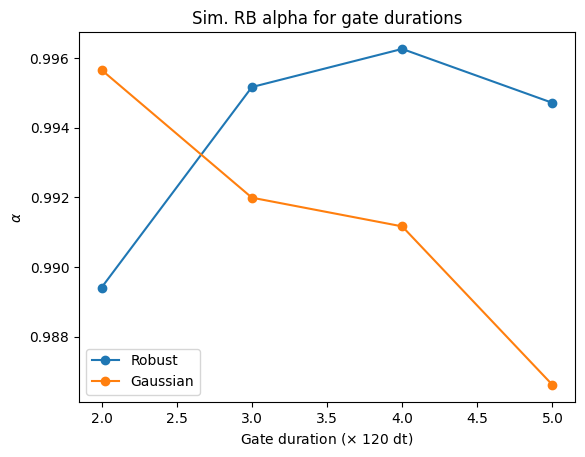

In [42]:
plt.plot(time, robust_alpha, label="Robust", marker="o")
plt.plot(time, gaussian_alpha, label="Gaussian", marker="o")
plt.title("Sim. RB alpha for gate durations")
plt.xlabel("Gate duration ($\\times$ 120 dt)")
plt.ylabel("$\\alpha$")
plt.legend();

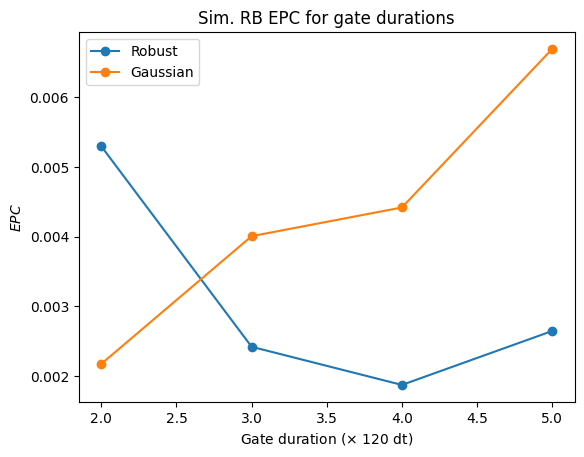

In [43]:
plt.plot(time, robust_epc, label="Robust", marker="o")
plt.plot(time, gaussian_epc, label="Gaussian", marker="o")
plt.title("Sim. RB EPC for gate durations")
plt.xlabel("Gate duration ($\\times$ 120 dt)")
plt.ylabel("$EPC$")
plt.legend();